##  Data Exploration & Data Pre-processing 

**Organization:** Break Through Tech AI Studio / MediMate Foundation  
**Milestone:** September Data Exporation and Pre-processing  
**Authors / Contributors:** Healthcare 1C Team  

---

### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
import os
import json

In [2]:
from pathlib import Path
import pandas as pd

# Find the repository whether VS Code starts in the repo root or notebooks/.
ROOT = next(
    (
        path for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "data" / "kidney_waitlist_analytic.csv.gz").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not find data/kidney_waitlist_analytic.csv.gz. "
        "Open the repository folder in VS Code and check that the dataset is present."
    )

DATA_DIR = ROOT / "data"
RAW_DATA_PATH = DATA_DIR / "kidney_waitlist_analytic.csv.gz"

df = pd.read_csv(RAW_DATA_PATH, low_memory=False)
print(f"Loaded {len(df):,} rows from {RAW_DATA_PATH}")



Loaded 494,862 rows from c:\Users\adeto\OneDrive\Dokumente\HealthCare 1C\Healthcare-1C-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation\data\kidney_waitlist_analytic.csv.gz


# Exploratory Data Analysis

In [3]:
df.head() #inpsect the first few rows of the dataset to understand its structure and contents.

,ON_DIALYSIS,A2A2B_ELIGIBILITY,GENDER,ABO,BMI_TCR,FUNC_STAT_TCR,INIT_STAT,INIT_CPRA,END_CPRA,REM_CD,...,PSTATUS,PTIME,TRR_ID_CODE,DONOR_ID,LISTING_CTR_CODE,outcome,event_adverse,event_transplant,censored,days_to_event
0,Y,NaN,F,B,31.63,2080.0,4099,0.0,0.0,8.0,...,NaN,NaN,NaN,NaN,13609,died,1,0,0,287.0
1,Y,NaN,M,A,30.04,2070.0,4099,0.0,NaN,24.0,...,NaN,NaN,NaN,NaN,6975,removed_administrative,0,0,0,2322.0
2,N,NaN,F,O,32.85,2070.0,4099,0.0,0.0,8.0,...,NaN,NaN,NaN,NaN,19716,died,1,0,0,604.0
3,Y,NaN,M,A,20.00,2090.0,4099,0.0,0.0,13.0,...,NaN,NaN,NaN,NaN,8587,removed_too_sick,1,0,0,909.0
4,Y,NaN,M,AB,23.30,2070.0,4010,0.0,0.0,13.0,...,NaN,NaN,NaN,NaN,18352,removed_too_sick,1,0,0,231.0


In [4]:
shape = df.shape # Check the number of rows and columns in the dataset to get an idea of its size
shape

(494862, 38)

In [5]:
columns = df.columns.to_list() 
columns

['ON_DIALYSIS',
 'A2A2B_ELIGIBILITY',
 'GENDER',
 'ABO',
 'BMI_TCR',
 'FUNC_STAT_TCR',
 'INIT_STAT',
 'INIT_CPRA',
 'END_CPRA',
 'REM_CD',
 'DAYSWAIT_CHRON',
 'END_STAT',
 'INIT_AGE',
 'DIALYSIS_DATE',
 'END_DATE',
 'INIT_DATE',
 'ETHCAT',
 'PT_CODE',
 'DAYSWAIT_ALLOC',
 'COMPOSITE_DEATH_DATE',
 'REGION',
 'WL_ID_CODE',
 'PREV_TX',
 'TX_DATE',
 'DON_TY',
 'DIAG_KI',
 'MULTIORG',
 'ORGAN',
 'PSTATUS',
 'PTIME',
 'TRR_ID_CODE',
 'DONOR_ID',
 'LISTING_CTR_CODE',
 'outcome',
 'event_adverse',
 'event_transplant',
 'censored',
 'days_to_event']

In [6]:
predict_classes = (df['outcome'].unique()).tolist() #List of unique values in the 'outcome' column, which represents the different classes that the model will predict. This is useful for understanding the target variable and for later use in model evaluation and interpretation.
predict_classes

['died',
 'removed_administrative',
 'removed_too_sick',
 'still_waiting',
 'transplanted_elsewhere',
 'unknown',
 'transplanted']

In [7]:
#Search for missing values in the dataset.
null_check = df.isnull().sum()
has_missing = [column for column in null_check.index if null_check[column] > 0]
for column in has_missing:
  print(f'{column} : {null_check[column]}')

A2A2B_ELIGIBILITY : 456604
BMI_TCR : 1558
FUNC_STAT_TCR : 3975
INIT_CPRA : 142741
END_CPRA : 142448
REM_CD : 103300
DAYSWAIT_CHRON : 53
DIALYSIS_DATE : 134245
DAYSWAIT_ALLOC : 6745
COMPOSITE_DEATH_DATE : 398512
PREV_TX : 264107
TX_DATE : 264107
DON_TY : 264107
DIAG_KI : 265540
MULTIORG : 483004
ORGAN : 264107
PSTATUS : 264107
PTIME : 267350
TRR_ID_CODE : 264107
DONOR_ID : 264107
days_to_event : 59


In [8]:
cat_cols = list((df.select_dtypes('object')).columns)
num_cols = list((df.select_dtypes(include = ['int64', 'float64'])).columns)

#Safety check for any columns that are neither numeric nor categorical, which could indicate unexpected data types or issues in the dataset.
[print (column, df[column].dtype) for column in columns if column not in num_cols and column not in cat_cols ]

C:\Users\adeto\AppData\Local\Temp\ipykernel_7656\96817454.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = list((df.select_dtypes('object')).columns)


[]

In [9]:
unique_cat_cols = {column : (df[column].nunique()) for column in cat_cols}
print(unique_cat_cols)

{'ON_DIALYSIS': 2, 'GENDER': 2, 'ABO': 8, 'DIALYSIS_DATE': 8953, 'END_DATE': 4196, 'INIT_DATE': 3805, 'COMPOSITE_DEATH_DATE': 4101, 'PREV_TX': 2, 'TX_DATE': 4189, 'DON_TY': 3, 'MULTIORG': 1, 'ORGAN': 2, 'TRR_ID_CODE': 230755, 'outcome': 7}


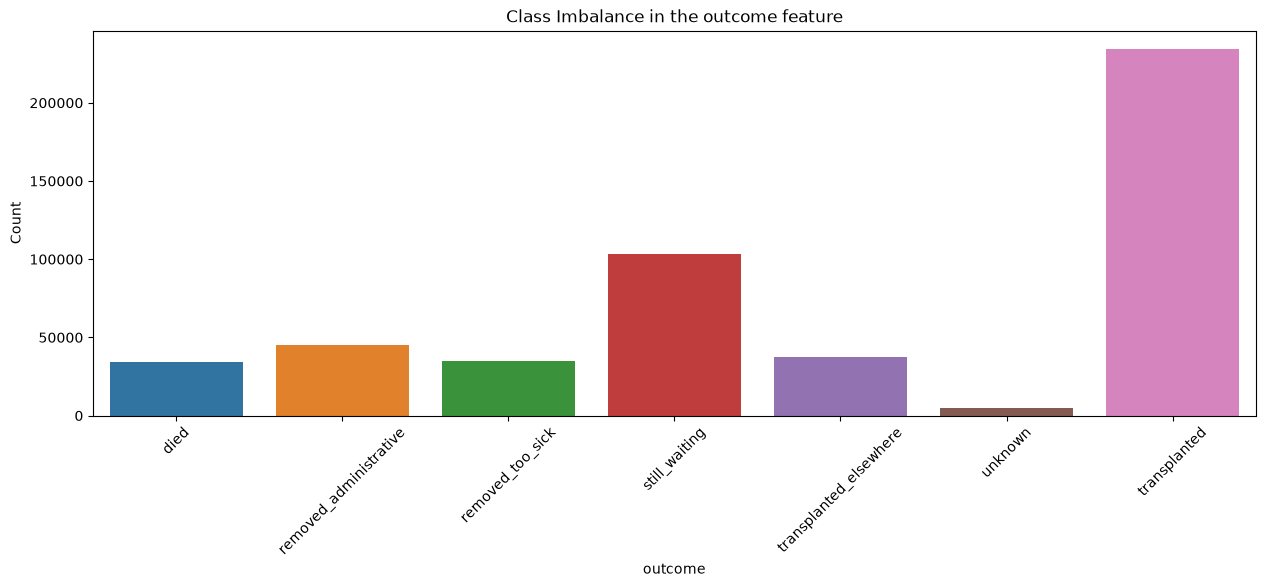

In [10]:
fig = plt.figure(figsize=(15,5))
ax = sns.countplot(x = df["outcome"], hue =df['outcome'])
plt.title(f'Class Imbalance in the {df["outcome"].name} feature')
plt.xlabel(f'{df["outcome"].name}')
plt.ylabel('Count')
plt.xticks(rotation = 45)
plt.show()

In [11]:
#Checking for the outliers in the numerical columns
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_bool = (df[num_cols] < lower_bound)| (df[num_cols] > upper_bound)

outliers = iqr_bool.any()
outliers = [column for column in outliers.index if outliers[column] == True]
outliers

['BMI_TCR',
 'FUNC_STAT_TCR',
 'INIT_CPRA',
 'REM_CD',
 'DAYSWAIT_CHRON',
 'INIT_AGE',
 'ETHCAT',
 'PT_CODE',
 'DAYSWAIT_ALLOC',
 'WL_ID_CODE',
 'DIAG_KI',
 'PSTATUS',
 'PTIME',
 'event_adverse',
 'censored',
 'days_to_event']

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 494862 entries, 0 to 494861
Data columns (total 38 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ON_DIALYSIS           494862 non-null  str    
 1   A2A2B_ELIGIBILITY     38258 non-null   float64
 2   GENDER                494862 non-null  str    
 3   ABO                   494862 non-null  str    
 4   BMI_TCR               493304 non-null  float64
 5   FUNC_STAT_TCR         490887 non-null  float64
 6   INIT_STAT             494862 non-null  int64  
 7   INIT_CPRA             352121 non-null  float64
 8   END_CPRA              352414 non-null  float64
 9   REM_CD                391562 non-null  float64
 10  DAYSWAIT_CHRON        494809 non-null  float64
 11  END_STAT              494862 non-null  int64  
 12  INIT_AGE              494862 non-null  int64  
 13  DIALYSIS_DATE         360617 non-null  str    
 14  END_DATE              494862 non-null  str    
 15  INIT_DATE  

In [13]:
df.describe()

,A2A2B_ELIGIBILITY,BMI_TCR,FUNC_STAT_TCR,INIT_STAT,INIT_CPRA,END_CPRA,REM_CD,DAYSWAIT_CHRON,END_STAT,INIT_AGE,...,WL_ID_CODE,DIAG_KI,PSTATUS,PTIME,DONOR_ID,LISTING_CTR_CODE,event_adverse,event_transplant,censored,days_to_event
count,38258.000000,493304.000000,490887.000000,494862.000000,352121.000000,352414.000000,391562.000000,494809.000000,494862.000000,494862.000000,...,4.948620e+05,229322.000000,230755.000000,227512.000000,230755.000000,494862.000000,494862.000000,494862.000000,494862.000000,494803.000000
mean,0.282242,64.700077,2106.332755,4036.217733,9.786130,29.219320,9.150027,649.532775,4038.288725,51.874533,...,1.595489e+06,2890.667337,0.119083,1241.054252,629284.062920,13040.187040,0.140934,0.473726,0.208745,649.541492
std,0.450096,3141.118209,343.735143,40.559675,24.799939,36.408157,5.932887,654.238307,41.437826,14.601018,...,2.306050e+05,534.282179,0.323887,947.761267,79431.124919,7742.892814,0.347954,0.499310,0.406412,654.237636
min,0.000000,0.180000,1.000000,4010.000000,0.000000,0.000000,4.000000,0.000000,4010.000000,0.000000,...,1.835720e+05,999.000000,0.000000,0.000000,415814.000000,124.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,24.650000,2070.000000,4010.000000,0.000000,0.000000,4.000000,144.000000,4010.000000,43.000000,...,1.397019e+06,3008.000000,0.000000,379.000000,565175.500000,6293.000000,0.000000,0.000000,0.000000,144.000000
50%,0.000000,28.530000,2080.000000,4010.000000,0.000000,6.860000,8.000000,433.000000,4010.000000,54.000000,...,1.597336e+06,3040.000000,0.000000,1087.000000,630483.000000,13454.000000,0.000000,0.000000,0.000000,433.000000
75%,1.000000,32.850000,2090.000000,4099.000000,0.000000,56.930000,14.000000,965.000000,4099.000000,63.000000,...,1.795160e+06,3070.000000,0.000000,1840.000000,696537.500000,19964.000000,0.000000,1.000000,0.000000,965.000000
max,1.000000,430226.670000,4100.000000,4099.000000,100.000000,100.000000,45.000000,4200.000000,4099.000000,91.000000,...,1.993444e+06,3074.000000,1.000000,4131.000000,767775.000000,27149.000000,1.000000,1.000000,1.000000,4200.000000


In [14]:
date_cols = [
    "INIT_DATE",
    "END_DATE",
    "DIALYSIS_DATE",
    "TX_DATE",
    "COMPOSITE_DEATH_DATE"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

date_quality = pd.Series({
    "missing_INIT_DATE": df["INIT_DATE"].isna().sum(),
    "END_DATE_before_INIT_DATE":
        (df["END_DATE"] < df["INIT_DATE"]).sum(),
    "TX_DATE_before_INIT_DATE":
        (df["TX_DATE"] < df["INIT_DATE"]).sum(),
    "death_date_before_INIT_DATE":
        (df["COMPOSITE_DEATH_DATE"] < df["INIT_DATE"]).sum(),
    "missing_days_to_event": df["days_to_event"].isna().sum(),
    "zero_day_events": df["days_to_event"].eq(0).sum()
})

display(date_quality.to_frame("count"))

,count
missing_INIT_DATE,0
END_DATE_before_INIT_DATE,59
TX_DATE_before_INIT_DATE,0
death_date_before_INIT_DATE,58
missing_days_to_event,59
zero_day_events,790


In [15]:
invalid_date_mask = df["END_DATE"] < df["INIT_DATE"]

print("Invalid END_DATE records:", invalid_date_mask.sum())

print(
    "Invalid END_DATE records with missing days_to_event:",
    df.loc[invalid_date_mask, "days_to_event"].isna().sum()
)

Invalid END_DATE records: 59
Invalid END_DATE records with missing days_to_event: 59


In [16]:
df_clean = df.loc[~invalid_date_mask].copy()

print("Original number of records:", len(df))
print("Invalid records excluded:", invalid_date_mask.sum())
print("Remaining records:", len(df_clean))

Original number of records: 494862
Invalid records excluded: 59
Remaining records: 494803


In [17]:
zero_day_events = df_clean[df_clean["days_to_event"] == 0]

print("Total zero-day events:", len(zero_day_events))
print("\nZero-day events by outcome:")
print(zero_day_events["outcome"].value_counts())

Total zero-day events: 790

Zero-day events by outcome:
outcome
removed_administrative    396
transplanted              260
removed_too_sick           67
unknown                    44
died                       18
transplanted_elsewhere      5
Name: count, dtype: int64


In [18]:
print(
    "Zero-day records where END_DATE equals INIT_DATE:",
    (zero_day_events["END_DATE"] == zero_day_events["INIT_DATE"]).sum()
)

print(
    "Zero-day records where END_DATE does NOT equal INIT_DATE:",
    (zero_day_events["END_DATE"] != zero_day_events["INIT_DATE"]).sum()
)

Zero-day records where END_DATE equals INIT_DATE: 790
Zero-day records where END_DATE does NOT equal INIT_DATE: 0


## Exploratory Data Analysis (EDA) Summary & Key Findings

An initial exploratory analysis was conducted on the kidney transplant waitlist dataset to understand data distributions, evaluate data quality, categorize features, and map out the preprocessing strategy. 

### 1. Feature Categorization & Selection
To prevent data leakage and ensure ethical modeling, the dataset's 38 original features were audited and classified into distinct categories:
* **Baseline Predictors (Retained):** Variables known at the time of listing, including `ON_DIALYSIS`, `A2A2B_ELIGIBILITY`, `ABO`, `BMI_TCR`, `FUNC_STAT_TCR`, `INIT_STAT`, `INIT_CPRA`, `INIT_AGE`, `DIALYSIS_DATE`, and `INIT_DATE`.
* **Sensitive Attributes:** Demographic data such as `GENDER`, `ETHCAT`, and `REGION`.
* **Identifiers (Excluded):** Tracking codes like `PT_CODE`, `WL_ID_CODE`, and `LISTING_CTR_CODE` (Identifier/Sensitive). 
* **Outcome/Future Variables (Excluded):** Metrics recorded post-listing or representing the target, such as `END_CPRA`, `REM_CD`, `DAYSWAIT_CHRON`, `END_STAT`, `END_DATE`, `COMPOSITE_DEATH_DATE`, `TX_DATE`, `outcome`, `event_adverse`, `days_to_event`, `PREV_TX`, and `DIAG_KI`. `TRR_ID_CODE` and `DONOR_ID` were also flagged as Identifier/Outcome variables.

### 2. Data Quality & Date Validation
A rigorous date validation check was performed by converting sequence columns to pandas datetime objects. The findings included:
* **Missing Dates:** `INIT_DATE` is 100% complete (0 missing).
* **Invalid Sequences:** 59 records showed `END_DATE` occurring before `INIT_DATE`, and 58 records had a `COMPOSITE_DEATH_DATE` preceding the `INIT_DATE`. Furthermore, 59 records were completely missing `days_to_event`. These structurally invalid rows were excluded from the modeling subset.
* **Zero-Day Events:** 790 records exhibited same-day events (`days_to_event == 0`). Investigation confirmed these are internally consistent (where `END_DATE` equals `INIT_DATE`) and were retained.

### 3. Missing Data & Demographic Disparities
Significant missingness was observed in several clinical features, which informed our imputation strategy:
* **cPRa Missingness Rates:** The Calculated Panel Reactive Antibody (`INIT_CPRA`) feature is missing in roughly 20-25% of records. 
* **Demographic Correlation:** Missingness in clinical data is heavily correlated with missing demographic identifiers. For example, patients in the "Unknown/Other" ethnic category (Category 998) showed an exceptionally high `INIT_CPRA` missingness rate of **82.58%**.

### 4. Outliers, Skewness, & Feature Distributions
* **Implausible Outliers:** Severe outliers were detected in continuous features like `BMI_TCR` (e.g., maximum values exceeding 400,000). IQR winsorization and clinical capping boundaries (e.g., BMI limited to 10–100) are required.
* **Functional Status (`FUNC_STATUS_PERCENT`):** Density estimation revealed that patients cluster heavily around "Mild-Moderate Limitation" (80%) and "Mostly Independent" (90%). This feature was binned into 7 distinct ordinal categories based on density valleys to preserve clinical thresholds.

### 5. Preprocessing Directives
Based on the identified dataset issues, the preprocessing pipeline is mapped as follows:
1. **Handling Missing Values:** Null and empty values will be resolved using central tendency measures. Continuous numerical features will be imputed using the column average/median, while categorical objects will be imputed using the mode (most frequent value). Binary missingness indicators will be retained for highly structured missingness (like `INIT_CPRA`).
2. **Encoding Non-Integer Values:** Machine learning models require strictly numerical input. All categorical features will be transformed using One-Hot Encoding.
3. **Normalization:** To prevent the model from becoming biased or disproportionately affected by continuous features with large magnitudes (e.g., age, duration), these variables will be normalized/scaled (converted into a 0–1 range).

# Data Pre-processing

### Defining the Clinical Target (1-Year Adverse Event)
In transplant analytics, setting a defined time horizon is crucial for survival and risk modeling. We define a 365-day horizon to capture early adverse events. The model's target is binary: candidates who died or became too sick for a transplant within one year are our positive class, while those who remained event-free or received a transplant are the negative class.

In [19]:
HORIZON_DAYS = 365

# Positive: died or removed as too sick within 365 days
positive_365 = (
    df["event_adverse"].eq(1)
    & df["days_to_event"].le(HORIZON_DAYS)
)

# Negative: observed for at least 365 days without an early adverse event
observed_one_year = df["days_to_event"].ge(HORIZON_DAYS)

# A transplant before 365 days is a definitive competing outcome
early_transplant = (
    df["outcome"].isin(["transplanted", "transplanted_elsewhere"])
    & df["days_to_event"].le(HORIZON_DAYS)
)

eligible_for_model = (
    (positive_365 | observed_one_year | early_transplant)
    & df["days_to_event"].notna()
    & df["outcome"].ne("unknown")
)

model_df = df.loc[eligible_for_model].copy()

model_df["adverse_365"] = (
    positive_365.loc[model_df.index]
    .astype(int)
)

print("Modeling rows:", len(model_df))
print(model_df["adverse_365"].value_counts())
print(model_df["adverse_365"].value_counts(normalize=True))

# The code handles candidates as follows:

#Target = 1: Died or was removed as too sick within 365 days.
#Target = 0: Remained adverse-event-free for at least 365 days.
#Target = 0: Received a transplant before 365 days, since transplant is treated as a competing outcome.
#Excluded: Still waiting with less than 365 days of observation because we do not yet know their one-year result.
#Excluded: Unknown outcomes and invalid follow-up dates.

Modeling rows: 439887
adverse_365
0    422300
1     17587
Name: count, dtype: int64
adverse_365
0    0.960019
1    0.039981
Name: proportion, dtype: float64


### Clinical Feature Engineering & Biological Plausibility
Raw clinical data often requires transformation to reflect true physiological states. We derive the exact duration of dialysis prior to listing (in years) to capture chronic disease burden. We also enforce biological plausibility by restricting Body Mass Index (BMI) values to a valid clinical range of 10 to 100, converting extreme data-entry errors into missing values to be imputed later.

In [20]:
# Dialysis had begun by the listing date
model_df["dialysis_at_listing"] = (
    model_df["DIALYSIS_DATE"].notna()
    & model_df["DIALYSIS_DATE"].le(model_df["INIT_DATE"])
).astype(int)

# Duration is only calculated when dialysis began by listing
dialysis_days = (
    model_df["INIT_DATE"] - model_df["DIALYSIS_DATE"]
).dt.days

model_df["dialysis_years_at_listing"] = np.where(
    model_df["dialysis_at_listing"].eq(1),
    dialysis_days / 365.25,
    0
)

# A2/A2B eligibility has different meanings for blood type B and non-B
model_df["A2A2B_STATUS"] = np.select(
    [
        model_df["ABO"].ne("B"),
        model_df["A2A2B_ELIGIBILITY"].eq(1),
        model_df["A2A2B_ELIGIBILITY"].eq(0)
    ],
    [
        "not_applicable",
        "eligible",
        "not_eligible"
    ],
    default="unknown"
)

# Provisional BMI quality rule
model_df["BMI_TCR_CLEAN"] = model_df["BMI_TCR"].where(
    model_df["BMI_TCR"].between(10, 100)
)

print(model_df[
    [
        "dialysis_at_listing",
        "dialysis_years_at_listing",
        "A2A2B_STATUS",
        "BMI_TCR_CLEAN"
    ]
].head())


   dialysis_at_listing  dialysis_years_at_listing    A2A2B_STATUS  \
0                    1                   1.987680         unknown   
1                    1                   2.496920  not_applicable   
2                    0                   0.000000  not_applicable   
3                    1                   1.240246  not_applicable   
4                    1                   1.070500  not_applicable   

   BMI_TCR_CLEAN  
0          31.63  
1          30.04  
2          32.85  
3          20.00  
4          23.30  


In [21]:
categorical_code_cols = [
    "INIT_STAT",
    "ETHCAT",
    "REGION"
]

for col in categorical_code_cols:
    model_df[col] = model_df[col].astype("string")

In [22]:
model_df["INIT_CPRA_CLEAN"] = model_df["INIT_CPRA"].where(
    model_df["INIT_CPRA"].between(0, 100)
)

model_df["INIT_CPRA_MISSING"] = (
    model_df["INIT_CPRA_CLEAN"].isna().astype(int)
)

### Standardizing Functional Status Scales
Candidate functional status is recorded using two different metrics: the Karnofsky Performance Status for adults and the Lansky Play Performance Scale for pediatrics. To prevent the model from misinterpreting these distinct coding systems, we split this information into two features: one capturing the pure functional percentage, and another identifying the clinical scale used.

In [23]:
func = model_df["FUNC_STAT_TCR"]

model_df["FUNC_STATUS_PERCENT"] = np.select(
    [
        func.between(2010, 2100),
        func.between(4010, 4100)
    ],
    [
        func - 2000,
        func - 4000
    ],
    default=np.nan
)

model_df["FUNC_STATUS_SCALE"] = np.select(
    [
        func.between(2010, 2100),
        func.between(4010, 4100),
        func.eq(996),
        func.eq(998),
        func.eq(1)
    ],
    [
        "adult_karnofsky",
        "pediatric_lansky",
        "not_applicable",
        "unknown",
        "adl_category"
    ],
    default="missing"
)

In [24]:
patient_listing_counts = model_df["PT_CODE"].value_counts()

print("Patients with multiple listings:",
      patient_listing_counts.gt(1).sum())

print("Maximum listings for one patient:",
      patient_listing_counts.max())

Patients with multiple listings: 52960
Maximum listings for one patient: 11


### Cohort Selection & Data Integrity Filtering
To prevent temporal data leakage and ensure a valid clinical cohort, we exclude any records containing negative follow-up days or missing event timelines.

In [25]:
model_df = model_df[
    model_df["days_to_event"].notna()
    & model_df["days_to_event"].ge(0)
].copy()
#This removes the 59 records with invalid date ordering.

In [26]:
categorical_features = [
    "ABO",
    "INIT_STAT",
    "A2A2B_STATUS",
    "FUNC_STATUS_SCALE"
]

for col in categorical_features:
    model_df[col] = model_df[col].fillna("unknown")

In [27]:
numeric_features = [
    "INIT_AGE",
    "BMI_TCR_CLEAN",
    "INIT_CPRA_CLEAN",
    "FUNC_STATUS_PERCENT",
    "dialysis_at_listing",
    "dialysis_years_at_listing"
]

categorical_features = [
    "ABO",
    "INIT_STAT",
    "A2A2B_STATUS",
    "FUNC_STATUS_SCALE",
    "GENDER",
    "ETHCAT",
    "REGION"
]

feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()
y = model_df["adverse_365"].copy()

# Used for splitting only, not as a predictor
groups = model_df["PT_CODE"].copy()

In [28]:
model_df['BMI_TCR_MISSING'] = model_df['BMI_TCR_CLEAN'].isna().astype(int)
model_df['INIT_CPRA_MISSING'] = model_df['INIT_CPRA_CLEAN'].isna().astype(int)

X['BMI_TCR_MISSING'] = model_df['BMI_TCR_MISSING'].loc[X.index]
X['INIT_CPRA_MISSING'] = model_df['INIT_CPRA_MISSING'].loc[X.index]

print("Missingness Indicators added:")
print("BMI_TCR_MISSING sum:", X['BMI_TCR_MISSING'].sum())
print("INIT_CPRA_MISSING sum:", X['INIT_CPRA_MISSING'].sum())
print("X shape:", X.shape)

Missingness Indicators added:
BMI_TCR_MISSING sum: 1623
INIT_CPRA_MISSING sum: 106860
X shape: (439887, 15)


### Missing Data Strategy: Robust Imputation
In healthcare datasets, missing lab results or vitals often occur systematically rather than at random. We use median imputation for continuous features (`BMI_TCR_CLEAN`, `INIT_CPRA_CLEAN`, and `FUNC_STATUS_PERCENT`) because the median is highly resistant to clinical outliers.

In [29]:
# 1. Calculate medians from unimputed data
bmi_median = X['BMI_TCR_CLEAN'].median()
cpra_median = X['INIT_CPRA_CLEAN'].median()
func_median = X['FUNC_STATUS_PERCENT'].median()

print(f"Calculated Medians:\n- BMI_TCR_CLEAN: {bmi_median}\n- INIT_CPRA_CLEAN: {cpra_median}\n- FUNC_STATUS_PERCENT: {func_median}\n")

# 2. Impute missing values with medians in X
X['BMI_TCR_CLEAN'] = X['BMI_TCR_CLEAN'].fillna(bmi_median)
X['INIT_CPRA_CLEAN'] = X['INIT_CPRA_CLEAN'].fillna(cpra_median)
X['FUNC_STATUS_PERCENT'] = X['FUNC_STATUS_PERCENT'].fillna(func_median)

# Also impute model_df to keep it synced
model_df['BMI_TCR_CLEAN'] = model_df['BMI_TCR_CLEAN'].fillna(bmi_median)
model_df['INIT_CPRA_CLEAN'] = model_df['INIT_CPRA_CLEAN'].fillna(cpra_median)
model_df['FUNC_STATUS_PERCENT'] = model_df['FUNC_STATUS_PERCENT'].fillna(func_median)

# 3. Confirm that no missing values remain for these columns
print("Null values in model_df:")
print(model_df[['BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT']].isna().sum())

print("\nNull values in X:")
print(X[['BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT']].isna().sum())


Calculated Medians:
- BMI_TCR_CLEAN: 28.51
- INIT_CPRA_CLEAN: 0.0
- FUNC_STATUS_PERCENT: 80.0

Null values in model_df:
BMI_TCR_CLEAN          0
INIT_CPRA_CLEAN        0
FUNC_STATUS_PERCENT    0
dtype: int64

Null values in X:
BMI_TCR_CLEAN          0
INIT_CPRA_CLEAN        0
FUNC_STATUS_PERCENT    0
dtype: int64


In [30]:
demographics = ['GENDER', 'ETHCAT', 'REGION']

for col in demographics:
    print(f'=== Missingness Rates of INIT_CPRA by {col} ===')
    grouped = model_df.groupby(col)['INIT_CPRA_MISSING'].mean() * 100
    counts = model_df.groupby(col).size()
    df_res = pd.DataFrame({
        'Missingness Rate (%)': grouped.round(2),
        'Total Records': counts
    })
    print(df_res.to_string())
    print('\n')

=== Missingness Rates of INIT_CPRA by GENDER ===
        Missingness Rate (%)  Total Records
GENDER                                     
F                      23.21         167157
M                      24.96         272730


=== Missingness Rates of INIT_CPRA by ETHCAT ===
        Missingness Rate (%)  Total Records
ETHCAT                                     
1                      23.06         181331
2                      23.28         128662
4                      27.54          86409
5                      24.30          32960
6                      22.53           3511
7                      26.25           2198
9                      26.81           3685
998                    82.58           1131


=== Missingness Rates of INIT_CPRA by REGION ===
        Missingness Rate (%)  Total Records
REGION                                     
1                      24.36          18243
10                     25.47          28770
11                     25.86          52915
2            

In [31]:
print("Columns in X:")
print(list(X.columns))
print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nChecking for any null values remaining in X:")
print(X.isnull().sum()[X.isnull().sum() > 0])
print("\nAlignment check (X index matches model_df and y index):", (X.index == y.index).all())

Columns in X:
['INIT_AGE', 'BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT', 'dialysis_at_listing', 'dialysis_years_at_listing', 'ABO', 'INIT_STAT', 'A2A2B_STATUS', 'FUNC_STATUS_SCALE', 'GENDER', 'ETHCAT', 'REGION', 'BMI_TCR_MISSING', 'INIT_CPRA_MISSING']

Shape of X: (439887, 15)
Shape of y: (439887,)

Checking for any null values remaining in X:
Series([], dtype: int64)

Alignment check (X index matches model_df and y index): True


In [32]:
# Verify that we do not perform imputation on BMI_TCR_CLEAN as requested
print("Null values in X for BMI_TCR_CLEAN:")
print(X['BMI_TCR_CLEAN'].isna().sum())

print('\nFinal columns of X:')
print(list(X.columns))
print('\nShape of X:', X.shape)

Null values in X for BMI_TCR_CLEAN:
0

Final columns of X:
['INIT_AGE', 'BMI_TCR_CLEAN', 'INIT_CPRA_CLEAN', 'FUNC_STATUS_PERCENT', 'dialysis_at_listing', 'dialysis_years_at_listing', 'ABO', 'INIT_STAT', 'A2A2B_STATUS', 'FUNC_STATUS_SCALE', 'GENDER', 'ETHCAT', 'REGION', 'BMI_TCR_MISSING', 'INIT_CPRA_MISSING']

Shape of X: (439887, 15)


### Outlier Mitigation (Winsorization)
Clinical data frequently contains extreme values that represent either true physiological extremes (the sickest patients) or severe data entry errors. Rather than dropping these valuable patient records, we apply IQR-based Winsorization. This statistically caps continuous variables at their lower and upper bounds, preserving the cohort size while preventing extreme values from distorting the machine learning gradients.

In [33]:
# Defining the continuous numerical columns to check for outliers
# (Excluding binary 'dialysis_at_listing' and highly skewed 'INIT_CPRA_CLEAN' which will be binned)
numerical_cols_for_outliers = [
    "INIT_AGE",
    "BMI_TCR_CLEAN",
    "FUNC_STATUS_PERCENT",
    "dialysis_years_at_listing"
]

# Looping through each column and cap the outliers using IQR
for col in numerical_cols_for_outliers:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Using the .clip() method to replace values outside the bounds with the bound values themselves
    X[col] = X[col].clip(lower=lower_bound, upper=upper_bound)

print("Outliers successfully capped to IQR boundaries.")

Outliers successfully capped to IQR boundaries.


### Clinical Risk Stratification (cPRA Binning)
The Calculated Panel Reactive Antibody (cPRA) represents a patient's immunological sensitization, but its distribution is highly skewed with a massive zero-inflation. To make this feature more clinically meaningful to the model, we map the continuous percentages into standard HRSA immunological risk brackets: Zero (0%), Moderate (1-20%), High (21-80%), and Very High/Sensitized (81-100%).

In [34]:
# Handling the zero-inflated skewness of INIT_CPRA_CLEAN via clinical binning
# We will use explicit bin edges based on standard HRSA clinical risk brackets:
# 0% (Zero), 1-20% (Moderate), 21-80% (High), 81-100% (Very High/Sensitized)

# Define bin edges. We use -0.1 to inclusively capture exactly 0.0.
bin_edges = [-0.1, 0, 20, 80, 100]
INIT_CPRA_CLEAN_labels = ['Zero', 'Moderate', 'High', 'Very High']

# Perform the binning
INIT_CPRA_CLEAN_BINNED = pd.cut(X['INIT_CPRA_CLEAN'], bins=bin_edges, labels=INIT_CPRA_CLEAN_labels)

print("Value counts for clinical bins:")
print(INIT_CPRA_CLEAN_BINNED.value_counts())
print("\n")

# Ordinal mapping of the categories
mapping = {'Zero': 0, 'Moderate': 1, 'High': 2, 'Very High': 3}

# Mapping the values into our feature set
X['INIT_CPRA_CLEAN_MAPPED'] = INIT_CPRA_CLEAN_BINNED.map(mapping).astype(float)
print(f"Unique numeric values for INIT_CPRA_CLEAN_MAPPED: {X['INIT_CPRA_CLEAN_MAPPED'].unique()}")

# Drop the original highly skewed column
if 'INIT_CPRA_CLEAN' in X.columns:
    X.drop(columns=['INIT_CPRA_CLEAN'], inplace=True)
    print("Successfully dropped original 'INIT_CPRA_CLEAN' column.")


Value counts for clinical bins:
INIT_CPRA_CLEAN
Zero         375009
High          27822
Moderate      20419
Very High     16637
Name: count, dtype: int64


Unique numeric values for INIT_CPRA_CLEAN_MAPPED: [0. 3. 2. 1.]
Successfully dropped original 'INIT_CPRA_CLEAN' column.


In [35]:
# Verify the new min and max values for the IQR-capped continuous variables
display(X[numerical_cols_for_outliers].describe().loc[['min', 'max']])

# Verify the mapped values for the binned CPRA column
print("\nValue counts for the new binned CPRA feature:")
display(X['INIT_CPRA_CLEAN_MAPPED'].value_counts())


,INIT_AGE,BMI_TCR_CLEAN,FUNC_STATUS_PERCENT,dialysis_years_at_listing
min,13.0,12.41,40.0,0.000000
max,90.0,45.05,100.0,5.318275



Value counts for the new binned CPRA feature:


INIT_CPRA_CLEAN_MAPPED
0.0    375009
2.0     27822
1.0     20419
3.0     16637
Name: count, dtype: int64

In [36]:
#Checking the number of unique categories in each categorical variable
print("Number of unique categories in each categorical feature in X:\n")
for category in categorical_features:
  print (f"{category}:  {X[category].unique()}\n Total number of unique categories in {category} = {len(X[category].unique())}\n\n")

Number of unique categories in each categorical feature in X:

ABO:  <StringArray>
['B', 'A', 'O', 'AB', 'A1', 'A2', 'A1B', 'A2B']
Length: 8, dtype: str
 Total number of unique categories in ABO = 8


INIT_STAT:  <StringArray>
['4099', '4010', '4050', '4060', '4020']
Length: 5, dtype: string
 Total number of unique categories in INIT_STAT = 5


A2A2B_STATUS:  <StringArray>
['unknown', 'not_applicable', 'not_eligible', 'eligible']
Length: 4, dtype: str
 Total number of unique categories in A2A2B_STATUS = 4


FUNC_STATUS_SCALE:  <StringArray>
['adult_karnofsky', 'pediatric_lansky', 'unknown', 'not_applicable',
 'missing']
Length: 5, dtype: str
 Total number of unique categories in FUNC_STATUS_SCALE = 5


GENDER:  <StringArray>
['F', 'M']
Length: 2, dtype: str
 Total number of unique categories in GENDER = 2


ETHCAT:  <StringArray>
['2', '1', '5', '4', '9', '6', '7', '998']
Length: 8, dtype: string
 Total number of unique categories in ETHCAT = 8


REGION:  <StringArray>
['8', '5', '11',

In [37]:
print (X.dtypes)

INIT_AGE                       int64
BMI_TCR_CLEAN                float64
FUNC_STATUS_PERCENT          float64
dialysis_at_listing            int64
dialysis_years_at_listing    float64
ABO                              str
INIT_STAT                     string
A2A2B_STATUS                     str
FUNC_STATUS_SCALE                str
GENDER                           str
ETHCAT                        string
REGION                        string
BMI_TCR_MISSING                int64
INIT_CPRA_MISSING              int64
INIT_CPRA_CLEAN_MAPPED       float64
dtype: object


### Categorical Encoding for Machine Learning
Algorithms require purely numeric inputs and can misinterpret nominal categories (like blood type or UNOS region) as having an ordinal ranking. We apply One-Hot Encoding to convert all categorical clinical and demographic features into a series of independent binary flags.

In [38]:
#One-Hot encoding the categorical features in X
X_categorical_encoded = pd.get_dummies( X[categorical_features], columns= categorical_features, prefix= categorical_features,dtype =int)
X = X.join(X_categorical_encoded)

X.drop(columns = categorical_features, inplace = True)


In [39]:
#Safe-check
for col in categorical_features:
  if col in X:
    print (f"{col} still in X")
  else:    print(f"{col} not in X")

ABO not in X
INIT_STAT not in X
A2A2B_STATUS not in X
FUNC_STATUS_SCALE not in X
GENDER not in X
ETHCAT not in X
REGION not in X









### Skewness Check

In [40]:
#Checking for Skewness in the continouos numerical columns
to_check = ['BMI_TCR_CLEAN', 'INIT_AGE', 'FUNC_STATUS_PERCENT', 'dialysis_years_at_listing']
skewed = []
for col in to_check:
  if (X[col].skew()) > 0.5 or (X[col].skew()) < -0.5:
    skewed.append(col)

    print(f"{col} has a skew of {X[col].skew()}")

INIT_AGE has a skew of -0.6391844555659789
FUNC_STATUS_PERCENT has a skew of -0.618600040132814
dialysis_years_at_listing has a skew of 1.2083253188549767


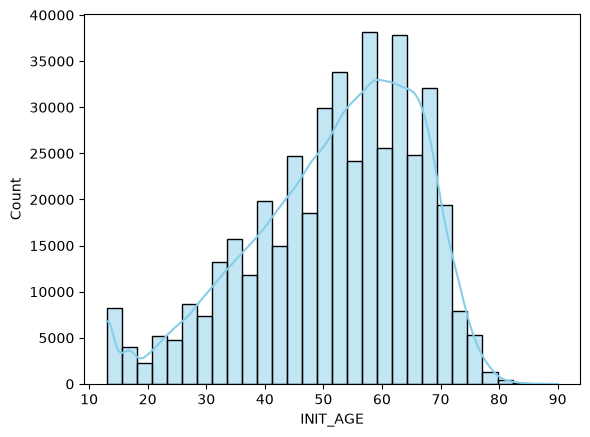

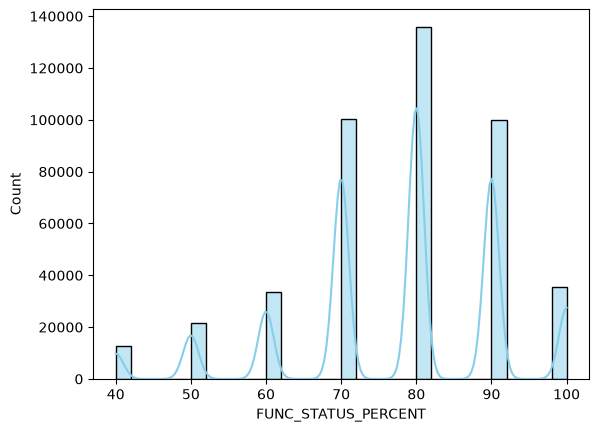

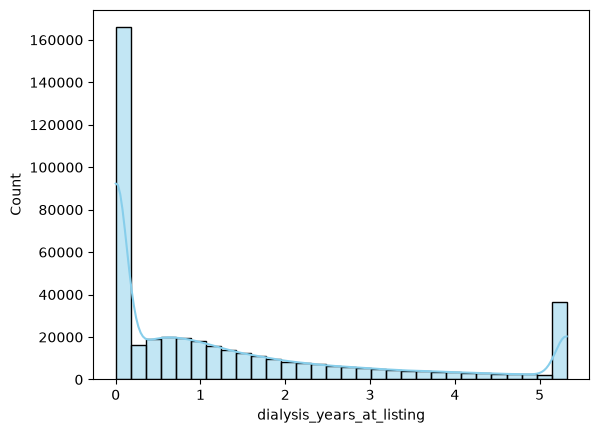

In [41]:
for col in skewed:
  sns.histplot(data=X, x= col, kde=True, bins=30, color="skyblue")
  plt.show()


Handling the "FUNC_STATUS_PERCENT" column by binning

In [42]:
#Binning for FUNC_STATUS_PERCENT
# Estimate smooth density
kde = gaussian_kde(X['FUNC_STATUS_PERCENT'])
x_axis = np.linspace(min(X['FUNC_STATUS_PERCENT']), max(X['FUNC_STATUS_PERCENT']), 1000)
density = kde(x_axis)

# Invert density and find the peaks of the inversion
valleys, _ = find_peaks(-density, prominence=0.001)

# Retrieving the actual data values at those valley indices
valley_values = x_axis[valleys]
print(f'The valley points are as follows: {valley_values}')

# Discovering the bins edges for binning
bin_edges = np.sort(np.concatenate([[X['FUNC_STATUS_PERCENT'].min()], valley_values, [X['FUNC_STATUS_PERCENT'].max()]]))
print(f'The bin edges are: {bin_edges}')

#Creating the labels for the bins
FUNC_STATUS_PERCENT_labels = [
    'Severe Limitation',
    'Major Limitation',
    'Moderate-Severe Limitation',
    'Moderate Limitation',
    'Mild-Moderate Limitation',
    'Mostly Independent',
    'Fully Independent'
]
FUNC_STATUS_PERCENT_BINNED = pd.cut(X['FUNC_STATUS_PERCENT'], bins=bin_edges, labels=FUNC_STATUS_PERCENT_labels, include_lowest=True)
print(f'The unique categories for FUNC_STATUS_PERCENT_BINNED {FUNC_STATUS_PERCENT_BINNED.unique()}')

#Ordinal mapping scale of the 7 categories
mapping = {
    'Severe Limitation': 0,
    'Major Limitation': 1,
    'Moderate-Severe Limitation': 2,
    'Moderate Limitation': 3,
    'Mild-Moderate Limitation': 4,
    'Mostly Independent': 5,
    'Fully Independent': 6
}

#Mapping the values
X['FUNC_STATUS_PERCENT_MAPPED'] = FUNC_STATUS_PERCENT_BINNED.map(mapping).astype(float)
print(f'The unique numbers for FUNC_STATUS_PERCENT_MAPPED {X["FUNC_STATUS_PERCENT_MAPPED"].unique()}')

# Correctly drop the original column
if 'FUNC_STATUS_PERCENT' in X.columns:
    X.drop(columns=['FUNC_STATUS_PERCENT'], inplace=True)
    print("Successfully dropped 'FUNC_STATUS_PERCENT' column.")


The valley points are as follows: [44.92492492 54.95495495 64.86486486 74.95495495 85.04504505 95.13513514]
The bin edges are: [ 40.          44.92492492  54.95495495  64.86486486  74.95495495
  85.04504505  95.13513514 100.        ]
The unique categories for FUNC_STATUS_PERCENT_BINNED ['Mild-Moderate Limitation', 'Moderate Limitation', 'Mostly Independent', 'Major Limitation', 'Fully Independent', 'Moderate-Severe Limitation', 'Severe Limitation']
Categories (7, str): ['Severe Limitation' < 'Major Limitation' < 'Moderate-Severe Limitation' < 'Moderate Limitation' < 'Mild-Moderate Limitation' < 'Mostly Independent' < 'Fully Independent']
The unique numbers for FUNC_STATUS_PERCENT_MAPPED [4. 3. 5. 1. 6. 2. 0.]
Successfully dropped 'FUNC_STATUS_PERCENT' column.


### Normalizing Skewed Distributions
Highly skewed continuous variables can bias model optimization. We apply logarithmic transformations to right-skewed features, specifically listing age and dialysis duration, to normalize their distributions and ensure the model weighs these temporal and demographic factors appropriately.

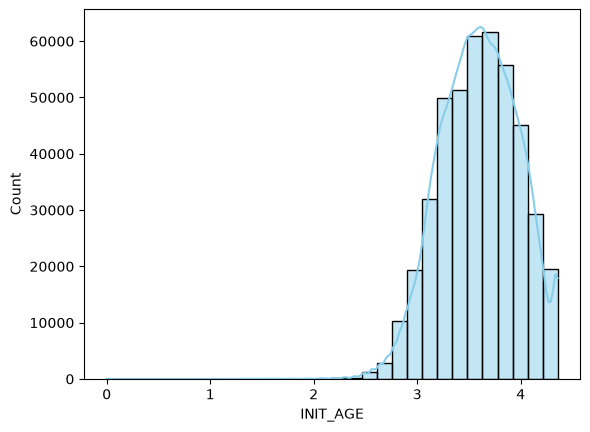

In [43]:
K = X['INIT_AGE'].max() + 1
X['INIT_AGE'] = np.log(K - X['INIT_AGE'])

sns.histplot(data=X, x= 'INIT_AGE', kde=True, bins=30, color="skyblue")
plt.show()


Handling dialysis_years_at_listing with a positive log transformation

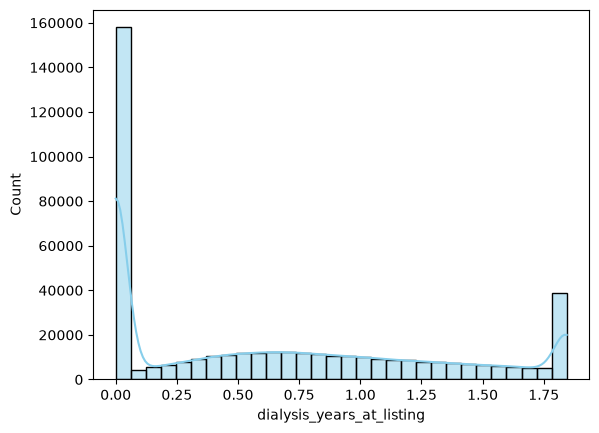

In [44]:
X['dialysis_years_at_listing'] = np.log1p(X['dialysis_years_at_listing'])

sns.histplot(data=X, x= 'dialysis_years_at_listing', kde=True, bins=30, color="skyblue")
plt.show()

In [45]:
## Examining the final dataset before processing

print('Checking the head of the X dataset:')
display(X.head())

print('\nChecking the shape of the X dataset:')
print(X.shape)

print('\nChecking the data types in the X dataset:')
display(X.dtypes)

print('\nChecking the statistics of the X dataset:')
display(X.describe())

print('\nChecking the amount of null values in the X dataset:')
display(X.isnull().sum())

Checking the head of the X dataset:


,INIT_AGE,BMI_TCR_CLEAN,dialysis_at_listing,dialysis_years_at_listing,BMI_TCR_MISSING,INIT_CPRA_MISSING,INIT_CPRA_CLEAN_MAPPED,ABO_A,ABO_A1,ABO_A1B,...,REGION_11,REGION_2,REGION_3,REGION_4,REGION_5,REGION_6,REGION_7,REGION_8,REGION_9,FUNC_STATUS_PERCENT_MAPPED
0,3.637586,31.63,1,1.094497,0,0,0.0,0,0,0,...,0,0,0,0,0,0,0,1,0,4.0
1,3.555348,30.04,1,1.251883,0,0,0.0,1,0,0,...,0,0,0,0,1,0,0,0,0,3.0
2,3.784190,32.85,0,0.000000,0,0,0.0,0,0,0,...,1,0,0,0,0,0,0,0,0,3.0
3,3.401197,20.00,1,0.806586,0,0,0.0,1,0,0,...,0,0,0,0,0,0,1,0,0,5.0
4,3.401197,23.30,1,0.727790,0,0,0.0,0,0,0,...,0,0,0,0,0,0,1,0,0,3.0



Checking the shape of the X dataset:
(439887, 51)

Checking the data types in the X dataset:


INIT_AGE                              float64
BMI_TCR_CLEAN                         float64
dialysis_at_listing                     int64
dialysis_years_at_listing             float64
BMI_TCR_MISSING                         int64
INIT_CPRA_MISSING                       int64
INIT_CPRA_CLEAN_MAPPED                float64
ABO_A                                   int64
ABO_A1                                  int64
ABO_A1B                                 int64
ABO_A2                                  int64
ABO_A2B                                 int64
ABO_AB                                  int64
ABO_B                                   int64
ABO_O                                   int64
INIT_STAT_4010                          int64
INIT_STAT_4020                          int64
INIT_STAT_4050                          int64
INIT_STAT_4060                          int64
INIT_STAT_4099                          int64
A2A2B_STATUS_eligible                   int64
A2A2B_STATUS_not_applicable       


Checking the statistics of the X dataset:


,INIT_AGE,BMI_TCR_CLEAN,dialysis_at_listing,dialysis_years_at_listing,BMI_TCR_MISSING,INIT_CPRA_MISSING,INIT_CPRA_CLEAN_MAPPED,ABO_A,ABO_A1,ABO_A1B,...,REGION_11,REGION_2,REGION_3,REGION_4,REGION_5,REGION_6,REGION_7,REGION_8,REGION_9,FUNC_STATUS_PERCENT_MAPPED
count,439887.000000,439887.000000,439887.000000,439887.000000,439887.00000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,...,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000,439887.000000
mean,3.598358,28.798068,0.650533,0.645674,0.00369,0.242926,0.286378,0.316472,0.005010,0.000475,...,0.120292,0.121661,0.139245,0.112813,0.166375,0.027439,0.081623,0.052700,0.070977,3.744009
std,0.373788,5.715551,0.476802,0.640999,0.06063,0.428851,0.746853,0.465100,0.070607,0.021792,...,0.325303,0.326894,0.346202,0.316365,0.372417,0.163359,0.273790,0.223434,0.256787,1.388124
min,0.000000,12.410000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.332205,24.650000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
50%,3.610918,28.510000,1.000000,0.527927,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,3.871201,32.810000,1.000000,1.140173,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000
max,4.356709,45.050000,1.000000,1.843446,1.00000,1.000000,3.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000



Checking the amount of null values in the X dataset:


INIT_AGE                              0
BMI_TCR_CLEAN                         0
dialysis_at_listing                   0
dialysis_years_at_listing             0
BMI_TCR_MISSING                       0
INIT_CPRA_MISSING                     0
INIT_CPRA_CLEAN_MAPPED                0
ABO_A                                 0
ABO_A1                                0
ABO_A1B                               0
ABO_A2                                0
ABO_A2B                               0
ABO_AB                                0
ABO_B                                 0
ABO_O                                 0
INIT_STAT_4010                        0
INIT_STAT_4020                        0
INIT_STAT_4050                        0
INIT_STAT_4060                        0
INIT_STAT_4099                        0
A2A2B_STATUS_eligible                 0
A2A2B_STATUS_not_applicable           0
A2A2B_STATUS_not_eligible             0
A2A2B_STATUS_unknown                  0
FUNC_STATUS_SCALE_adult_karnofsky     0


### Normalization

In [46]:
scaler = StandardScaler()

for col in numeric_features:
  if col in X and col != 'dialysis_at_listing':
    X[col] = scaler.fit_transform(X[[col]])

### Saving Relevant File changes

In [47]:
OUTPUT_DIR = ROOT / "processed_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_PATH = OUTPUT_DIR / "X_processed.csv"
Y_PATH = OUTPUT_DIR / "y_processed.csv"

REBUILD = False 

METADATA_PATH = OUTPUT_DIR / "dataset_metadata.json"

metadata = {
    "num_samples": int(len(X)),
    "num_features": int(X.shape[1]),
    "feature_names": X.columns.tolist(),
    "target_name": str(y.name),
    "class_distribution": {
        str(label): int(count)
        for label, count in y.value_counts().items()
    },
}

output_paths = [X_PATH, Y_PATH, METADATA_PATH]
existing = [path.exists() for path in output_paths]

if all(existing) and not REBUILD:
    print("Processed data and metadata already exist; skipping save.")
elif any(existing) and not REBUILD:
    raise FileExistsError(
        "Some output files exist, but others are missing. "
        "Check the files or set REBUILD = True to regenerate all outputs."
    )
else:
    X.to_csv(X_PATH, index=True)
    y.to_frame().to_csv(Y_PATH, index=True)

    with METADATA_PATH.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2)

    print("Saved processed features, target, and metadata.")

Processed data and metadata already exist; skipping save.


## Data Preprocessing & Feature Engineering Summary

This section details the data transformation pipeline designed to convert raw kidney transplant waitlist data into a robust, machine-learning-ready feature matrix. The pipeline is engineered to prevent data leakage, handle high-cardinality clinical scales, resolve extreme skewness, and establish a clear classification target.

### 1. Target Variable Engineering (`adverse_365`) & Data Splitting Strategy
To establish a clear classification problem, the modeling horizon was set to **365 days** (`HORIZON_DAYS = 365`). 
* **Target Definition:** A positive class (`1`) is defined as a candidate who died or was removed from the waitlist as "too sick" within 365 days of listing. The negative class (`0`) includes candidates who remained adverse-event-free for at least 365 days or received a transplant before 365 days (treated as a competing outcome).
* **Dataset Reduction:** Invalid follow-up dates and unknown outcomes were excluded. However, 790 "zero-day" events were validated as internally consistent (where listing and event occurred on the same day) and were retained. The final modeling subset contains **439,887 eligible records**, exhibiting a highly imbalanced class distribution (~96.0% negative, ~4.0% positive).
* **Patient Grouping (Leakage Prevention):** Analysis of `PT_CODE` revealed that 52,960 patients have multiple waitlist registrations (up to 11 per patient). A distinct `groups` array was isolated alongside the feature matrix to ensure future train/test splits use grouped cross-validation, preventing data leakage across splits.

### 2. Clinical Feature Engineering
To ensure the model only learns from information available at the time of initial waitlist listing, several baseline predictors were engineered from raw chronological and clinical data:

* **Dialysis Status at Listing:** The `dialysis_at_listing` binary variable identifies whether a candidate had strictly begun dialysis on or before their initial listing date, replacing the less precise `ON_DIALYSIS` flag. 
* **Dialysis Duration at Listing (`dialysis_years_at_listing`):** Calculates the exact duration (in years) a candidate received dialysis prior to waitlist entry. Candidates who began dialysis post-listing are assigned a duration of zero, strictly preventing future information leakage.
* **A2 and A2B Eligibility Status:** The raw eligibility field was reorganized into four distinct categories (`eligible`, `not_eligible`, `not_applicable`, `unknown`) to differentiate between missing data and candidates (e.g., non-Blood Type B) for whom the pathway does not apply.
* **Calculated Panel Reactive Antibody (cPRA):** cPRA estimates the percentage of potential deceased donors whose organs would be immunologically incompatible due to the candidate’s HLA antibodies (ranging from 0 to 100). 
    * `INIT_CPRA` was retained as the baseline measurement, while `END_CPRA` was excluded to prevent data leakage. 
    * A value of 0 is treated as a legitimate, highly compatible state, not a missing value.
* **Functional Status Parsing (`FUNC_STAT_TCR`):** The raw functional status variable natively blends two discrete grading systems (Adult Karnofsky Performance Status and Pediatric Lansky Play Performance Scale) alongside special codes. This was parsed into two separate features:
    * `FUNC_STATUS_PERCENT`: The candidate's pure functional percentage score (40% to 100%).
    * `FUNC_STATUS_SCALE`: A categorical label (`adult_karnofsky`, `pediatric_lansky`, `adl_category`, `not_applicable`, `unknown`) preventing the model from conflating pediatric and adult scales.
* **Cleaned BMI:** `BMI_TCR_CLEAN` provisionally bounds Body Mass Index values between 10 and 100, effectively muting highly implausible administrative errors (e.g., maximums exceeding 430,000) prior to imputation.

### 3. Missing Data Imputation & Indicators
A targeted imputation strategy was deployed to address missing clinical markers without losing the predictive signal of the missingness itself:

Significant missingness was observed in the Calculated Panel Reactive Antibody (`INIT_CPRA`) feature, which informed our missingness-indicator strategy. An analysis of demographic disparities revealed:
* **Gender**: Missingness rates for `INIT_CPRA` are slightly higher in males (**24.96%** across 272,730 records) compared to females (**23.21%** across 167,157 records).
* **Race/Ethnicity (ETHCAT)**: While most ethnic groups hover between **22.53%** and **27.54%** missingness, Category **998** (representing Unknown/Other) exhibits an exceptionally high missingness rate of **82.58%**. This points to a strong systematic correlation where missing demographic details correspond to missing clinical data.
* **Geographic Region**: Missingness shows geographic variation across US Organ Procurement Regions, with Region 6 showing the lowest rate (**18.11%**) and Region 8 showing the highest (**27.29%**).
* **Median Imputation:** After establishing the missingness indicators, the continuous columns `BMI_TCR_CLEAN`, `INIT_CPRA_CLEAN`, and `FUNC_STATUS_PERCENT` were imputed using their respective training medians (28.51, 0.0, and 80.0) to establish a complete matrix.

### 4. Outlier Mitigation & Skewness Resolution
Distributional abnormalities and severe outliers were managed through a combination of statistical clipping, algorithmic binning, and logarithmic transformations:
* **IQR Winsorization:** Extreme outliers in continuous variables (`INIT_AGE`, `BMI_TCR_CLEAN`, `FUNC_STATUS_PERCENT`, `dialysis_years_at_listing`) were capped at their respective Interquartile Range (IQR) lower and upper bounds.
* **Logarithmic Transformations:** 
    * `INIT_AGE` (left-skewed, -0.63) was resolved via a Negative Log Transformation.
    * `dialysis_years_at_listing` (right-skewed, +1.20) was normalized using a Positive Log Transformation (`log1p`).
* **Clinical Binning (cPRA):** To resolve the zero-inflated skew of `INIT_CPRA`, the feature was converted into an ordinal scale based on standard clinical risk brackets: Zero (0), Moderate (1-20), High (21-80), and Very High (81-100).
* **Algorithmic Binning (Functional Status):** Density estimation (Gaussian KDE) was applied to `FUNC_STATUS_PERCENT` to map the real distribution of patient vitality. By identifying local minima (valleys) in the density curves, the continuous percentages were segmented into 7 distinct ordinal categories ranging from "Severe Limitation" (0) to "Fully Independent" (6). The patient population heavily clusters around "Mild-Moderate Limitation" (80%) and "Mostly Independent" (90%).

### 5. Encoding & Feature Scaling
To fulfill standard machine learning algorithmic requirements:
* **Categorical Imputation:** Before encoding, any remaining missing values in categorical features (`ABO`, `INIT_STAT`, `A2A2B_STATUS`, `FUNC_STATUS_SCALE`) were explicitly filled with an `"unknown"` label.
* **One-Hot Encoding:** All categorical variables (`ABO`, `INIT_STAT`, `A2A2B_STATUS`, `FUNC_STATUS_SCALE`, `GENDER`, `ETHCAT`, `REGION`) were transformed into discrete binary columns, expanding the feature space to 51 columns.
* **Standardization:** `StandardScaler` was applied to all non-binary numeric continuous features to ensure uniform variance and magnitude across inputs, preventing variables like age or BMI from disproportionately dominating the model's loss function.
### 6. Final Data Export
The fully processed, normalized, and encoded feature matrix (`X_processed`) and target vector (`y_processed`) were exported to Google Drive as compressed `.csv.gz` files. The final matrix contains **439,887 records and 51 features** with zero remaining null values. A companion JSON metadata file was simultaneously generated to record matrix dimensions, class distribution, and exact feature names for the downstream modeling phase.